# Notebook 03: Middenhuis Data Exploratie 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt


DATA_DIR = Path.cwd().parent / "locatie_data"

In [2]:
df_middenhuis = pd.read_parquet(
    DATA_DIR / "middenhuis479.parquet"
)

In [3]:
df_middenhuis.head()

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CO2,ENE,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdmeter-5335bae8d497,powermeter,240308_hoofdmeter-5335bae8d497_583371188e6bd6b...,240308_hoofdmeter-5335bae8d497_583371188e6bd6b...,hoofdmeter-5335bae8d497,NaN,NaN,...,NaN,supply,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,overigverbruik-5335bae8d497,powermeter,240308_overigverbruik-5335bae8d497_583371188e6...,240308_overigverbruik-5335bae8d497_583371188e6...,overigverbruik-5335bae8d497,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,NaN,NaN,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:05:00+01:00,184.0,electricity,co2ele_combined,co2equivalent,240308_co2ele_92be2eca45_740e1a9dd5d5a483bdfc0...,240308_co2ele_92be2eca45_740e1a9dd5d5a483bdfc0...,co2ele_92be2eca45,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:05:00+01:00,NaN,electricity,hoofdmeter-5335bae8d497,powermeter,240308_hoofdmeter-5335bae8d497_583371188e6bd6b...,240308_hoofdmeter-5335bae8d497_583371188e6bd6b...,hoofdmeter-5335bae8d497,1.765482,9.595011,...,NaN,supply,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Algemene controle

In [4]:
print("Shape:", df_middenhuis.shape)
print("Chronologisch:", df_middenhuis["timestamp"].is_monotonic_increasing)

df_middenhuis.info()

Shape: (3493093, 25)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 3493093 entries, 0 to 3493092
Data columns (total 25 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2EQ          float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ETYPE          str                             
 5   source_zip     str                             
 6   source_csv     str                             
 7   source_folder  str                             
 8   CO2            float64                         
 9   ENE            float64                         
 10  POW            float64                         
 11  CO2_EXP        float64                         
 12  CO2_IMP        float64                         
 13  COST           float64                         
 14  COST

In [5]:
df_middenhuis["ENAME"].value_counts()

ENAME
hoofdmeter-5335bae8d497              397491
totaalverbruik-5335bae8d497          397491
overigverbruik-5335bae8d497          397461
drinkwaterpompen-5335bae8d497        370734
omvormer-5335bae8d497                364859
droger-5335bae8d497                  343214
wasmachine1-5335bae8d497             335969
helofytenfilterpomp-5335bae8d497     333852
priceele_c911efafaa                  171217
co2ele_combined                      166360
odectprice_c911efafaa                 95109
wasmachine2-5335bae8d497              83311
forec-omvormer-5335bae8d497           17294
forec-totaalverbruik-5335bae8d497     17294
priceele_123456                        1437
Name: count, dtype: int64

In [6]:
# Ingevulde waarden per ENAME
ingevulde_kolommen_per_ename = (df_middenhuis.groupby("ENAME").count())

ingevulde_kolommen_per_ename

,timestamp,CO2EQ,CTYPE,ETYPE,source_zip,source_csv,source_folder,CO2,ENE,POW,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
ENAME,,,,,,,,,,,,,,,,,,,,,
co2ele_combined,166360,166360,166360,166360,166360,166360,166360,0,0,0,...,0,0,0,0,0,0,0,0,0,0
drinkwaterpompen-5335bae8d497,370734,0,370734,370734,370734,370734,370734,126170,194940,100759,...,165030,166101,164351,165084,164308,165042,0,0,0,0
droger-5335bae8d497,343214,0,343214,343214,343214,343214,343214,111175,176742,61481,...,164684,165111,164182,164739,164139,164697,0,0,0,0
forec-omvormer-5335bae8d497,17294,0,17294,17294,17294,17294,17294,0,0,0,...,0,17294,0,0,0,0,17294,8647,8647,0
forec-totaalverbruik-5335bae8d497,17294,0,17294,17294,17294,17294,17294,0,0,0,...,0,17294,0,0,0,0,17294,8647,8647,0
helofytenfilterpomp-5335bae8d497,333852,0,333852,333852,333852,333852,333852,104664,167277,65326,...,165038,165150,164461,165092,164420,165050,0,0,0,0
hoofdmeter-5335bae8d497,397491,0,397491,397491,397491,397491,397491,155107,228916,206815,...,167265,228988,167189,167321,168141,182996,0,0,0,0
odectprice_c911efafaa,95109,0,95109,95109,95109,95109,95109,0,0,0,...,0,95109,0,0,0,0,0,0,0,95109
omvormer-5335bae8d497,364859,0,364859,364859,364859,364859,364859,127990,195733,121546,...,166672,197097,167217,166728,167173,166683,0,0,0,0


### Overzicht van de meetreeksen

In [7]:
# maakt per ENAME een samenvatting vd timestamps 
overzicht = (df_middenhuis.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"), # telt hoeveel rijen er per ENAME zijn 
        unieke_timestamps=("timestamp", "nunique"), # telt hoeveel verschillende timestamps er per ENAME zijn 
        eerste_meting=("timestamp", "min"), # eerste timestamp die voorkomt per ENAME 
        laatste_meting=("timestamp", "max") # laatste timestamp die voorkomt per ENAME
    )
)

# berekent hoeveel extra rijen er zijn doordat timestamps vaker dan 1 keer voorkomen 
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
hoofdmeter-5335bae8d497,397491,228987,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168504
totaalverbruik-5335bae8d497,397491,228988,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168503
overigverbruik-5335bae8d497,397461,228973,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168488
drinkwaterpompen-5335bae8d497,370734,204632,2024-03-08 01:20:00+01:00,2026-09-10 01:55:00+02:00,166102
omvormer-5335bae8d497,364859,197097,2024-03-08 07:20:00+01:00,2026-09-10 01:55:00+02:00,167762
droger-5335bae8d497,343214,178103,2024-03-08 11:05:00+01:00,2026-09-10 01:55:00+02:00,165111
wasmachine1-5335bae8d497,335969,171287,2024-03-08 11:05:00+01:00,2026-09-10 01:55:00+02:00,164682
helofytenfilterpomp-5335bae8d497,333852,168702,2024-03-08 08:15:00+01:00,2026-09-10 01:55:00+02:00,165150
priceele_c911efafaa,171217,171217,2025-01-14 09:20:00+01:00,2026-09-10 01:55:00+02:00,0


### Totaalverbruik bekijken

In [8]:
TOTAALVERBRUIK = "totaalverbruik-5335bae8d497"

# aparte dataframe met alleen de rijen van totaalverbruik
df_totaal = (df_middenhuis[df_middenhuis["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())

# berekent hoeveel extra rijen er zijn doordat timestamps vaker voorkomen
print("Dubbele timestamps:",
    len(df_totaal) - df_totaal["timestamp"].nunique()
)

df_totaal.head()

Aantal rijen: 397491
Unieke timestamps: 228988
Dubbele timestamps: 168503


,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CO2,ENE,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,NaN,NaN,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,1.766796,9.602151,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,1.767013,9.603333,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,1.765484,9.595020,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,240308_totaalverbruik-5335bae8d497_583371188e6...,240308_totaalverbruik-5335bae8d497_583371188e6...,totaalverbruik-5335bae8d497,1.761289,9.572222,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df_dubbel = (df_totaal[df_totaal["timestamp"].duplicated(keep=False)].sort_values("timestamp"))

df_dubbel

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CO2,ENE,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
42593,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,241005_totaalverbruik-5335bae8d497_c44928fd385...,241005_totaalverbruik-5335bae8d497_c44928fd385...,totaalverbruik-5335bae8d497,44.485647,NaN,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42594,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,241005_totaalverbruik-5335bae8d497_c44928fd385...,241005_totaalverbruik-5335bae8d497_c44928fd385...,totaalverbruik-5335bae8d497,NaN,93.457243,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60462,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,totaalverbruik-5335bae8d497,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60463,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,totaalverbruik-5335bae8d497,30.005104,95.254299,...,NaN,consumption,0.0,41840.0,NaN,NaN,NaN,NaN,NaN,NaN
60464,2025-01-14 09:25:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,250114_totaalverbruik-5335bae8d497_1e06bd2cb94...,totaalverbruik-5335bae8d497,NaN,NaN,...,0.050055,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397486,2026-09-10 01:45:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,260909_totaalverbruik-5335bae8d497_1b5c260e149...,260909_totaalverbruik-5335bae8d497_1b5c260e149...,totaalverbruik-5335bae8d497,NaN,NaN,...,0.003557,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397487,2026-09-10 01:50:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,260909_totaalverbruik-5335bae8d497_1b5c260e149...,260909_totaalverbruik-5335bae8d497_1b5c260e149...,totaalverbruik-5335bae8d497,7.030000,19.000000,...,NaN,consumption,0.0,11547618.0,0.0,19.0,NaN,NaN,NaN,NaN
397488,2026-09-10 01:50:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,260909_totaalverbruik-5335bae8d497_1b5c260e149...,260909_totaalverbruik-5335bae8d497_1b5c260e149...,totaalverbruik-5335bae8d497,NaN,NaN,...,0.004828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397489,2026-09-10 01:55:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,260909_totaalverbruik-5335bae8d497_1b5c260e149...,260909_totaalverbruik-5335bae8d497_1b5c260e149...,totaalverbruik-5335bae8d497,21.460000,58.000000,...,NaN,consumption,0.0,11547676.0,0.0,58.0,NaN,NaN,NaN,NaN


### POW bekijken 

In [10]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,115.225806
1,2024-03-08 01:05:00+01:00,115.240000
2,2024-03-08 01:10:00+01:00,115.140244
3,2024-03-08 01:15:00+01:00,114.866667
4,2024-03-08 01:20:00+01:00,115.363636


In [11]:
print("Ontbrekende POW:", df_totaal["POW"].isna().sum())

Ontbrekende POW: 190706


In [12]:
df_totaal['POW'].describe().T

count    206785.000000
mean        719.362716
std         817.446132
min       -4456.167382
25%         182.889447
50%         439.078212
75%         967.396078
max        9938.500000
Name: POW, dtype: float64

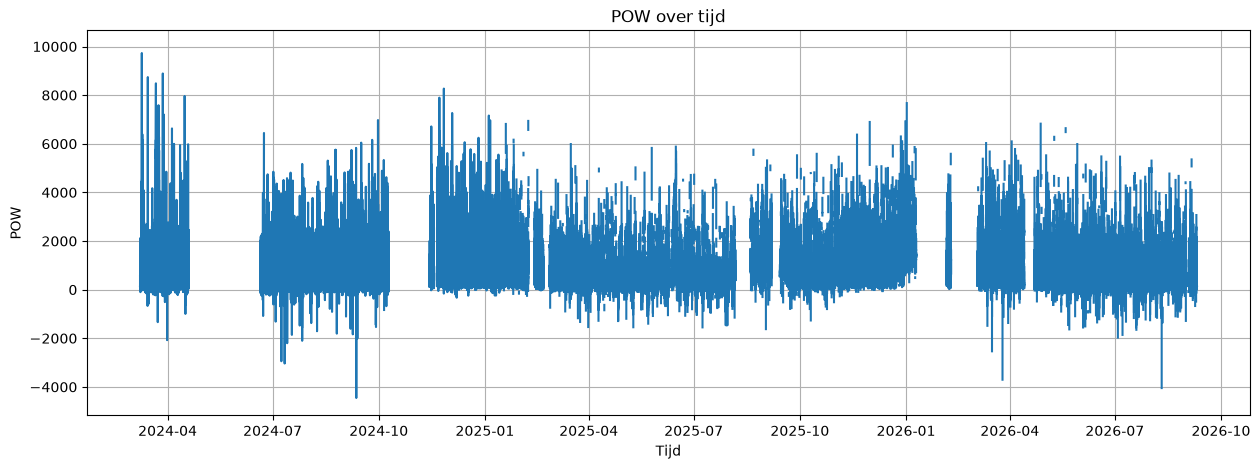

In [13]:
# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [14]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

print(
    "Laatste timestamp met geldige POW:",
    df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max()
)

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-10 01:55:00+02:00
Laatste timestamp met geldige POW: 2026-09-10 01:55:00+02:00


In [15]:
df_middenhuis_pow = df_middenhuis[
    df_middenhuis["POW"].notna()
].copy()

In [16]:
controle_pow = (
    df_middenhuis_pow
    .groupby(
        [
            "timestamp",
            "CTYPE",
            "CTYPEC",
            "ENAME",
            "ETYPE"
        ],
        dropna=False
    )
    .agg(
        aantal_rijen=("POW", "size"),
        aantal_unieke_POW=("POW", "nunique"),
        min_POW=("POW", "min"),
        max_POW=("POW", "max")
    )
    .reset_index()
)

controle_pow = controle_pow[
    controle_pow["aantal_rijen"] > 1
]

controle_pow.head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,aantal_rijen,aantal_unieke_POW,min_POW,max_POW
194613,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-5335bae8d497,powermeter,2,2,427.141304,1108.205882
194615,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-5335bae8d497,powermeter,2,2,403.530000,1110.641026
194616,2024-10-05 20:10:00+02:00,electricity,NaN,drinkwaterpompen-5335bae8d497,powermeter,2,2,111.375000,206.947826
194619,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-5335bae8d497,powermeter,2,2,243.897727,993.382353


### Punt 3 check?

In [17]:
#Alleen rijen waar POW aanwezig is
df_pow = df_middenhuis[df_middenhuis["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CO2,ENE,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
236034,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,241005_totaalverbruik-5335bae8d497_c44928fd385...,241005_totaalverbruik-5335bae8d497_c44928fd385...,totaalverbruik-5335bae8d497,44.485647,NaN,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236035,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-5335bae8d497,powermeter,241005_totaalverbruik-5335bae8d497_c44928fd385...,241005_totaalverbruik-5335bae8d497_c44928fd385...,totaalverbruik-5335bae8d497,NaN,93.457243,...,NaN,consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236029,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdmeter-5335bae8d497,powermeter,241005_hoofdmeter-5335bae8d497_c44928fd3855fba...,241005_hoofdmeter-5335bae8d497_c44928fd3855fba...,hoofdmeter-5335bae8d497,46.406394,NaN,...,NaN,supply,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236030,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdmeter-5335bae8d497,powermeter,241005_hoofdmeter-5335bae8d497_c44928fd3855fba...,241005_hoofdmeter-5335bae8d497_c44928fd3855fba...,hoofdmeter-5335bae8d497,NaN,97.492424,...,NaN,supply,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236025,2024-10-05 20:10:00+02:00,NaN,electricity,drinkwaterpompen-5335bae8d497,powermeter,241005_drinkwaterpompen-5335bae8d497_b64e2a426...,241005_drinkwaterpompen-5335bae8d497_b64e2a426...,drinkwaterpompen-5335bae8d497,22.497611,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236026,2024-10-05 20:10:00+02:00,NaN,electricity,drinkwaterpompen-5335bae8d497,powermeter,241005_drinkwaterpompen-5335bae8d497_b64e2a426...,241005_drinkwaterpompen-5335bae8d497_b64e2a426...,drinkwaterpompen-5335bae8d497,NaN,47.263889,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236032,2024-10-05 20:10:00+02:00,NaN,electricity,overigverbruik-5335bae8d497,powermeter,241005_overigverbruik-5335bae8d497_c44928fd385...,241005_overigverbruik-5335bae8d497_c44928fd385...,overigverbruik-5335bae8d497,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236033,2024-10-05 20:10:00+02:00,NaN,electricity,overigverbruik-5335bae8d497,powermeter,241005_overigverbruik-5335bae8d497_c44928fd385...,241005_overigverbruik-5335bae8d497_c44928fd385...,overigverbruik-5335bae8d497,21.072124,43.808989,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
236034,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-5335bae8d497,powermeter,427.141304
236035,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-5335bae8d497,powermeter,1108.205882
236029,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-5335bae8d497,powermeter,403.530000
236030,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-5335bae8d497,powermeter,1110.641026
236025,2024-10-05 20:10:00+02:00,electricity,NaN,drinkwaterpompen-5335bae8d497,powermeter,206.947826
236026,2024-10-05 20:10:00+02:00,electricity,NaN,drinkwaterpompen-5335bae8d497,powermeter,111.375000
236032,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-5335bae8d497,powermeter,243.897727
236033,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-5335bae8d497,powermeter,993.382353
